# Programming Lab 1

Recep Çil

## Homework assignment

Create the following circuit. Start with the state $|0\rangle$ and apply $R_y(\theta)$ for $\theta \in [0, 2\pi)$ by taking $20$ discrete points (with equal distances) in the interval, and then measure the qubit. For each point, calculate the average value of $Z$, i.e. perform a measurement in the computational basis with `shots=2048` and calculate the average value. Use the `AerSimulator` backend. Plot the average value of $Z$ against $\theta$.

## Solution

In [ ]:
%pip install qiskit qiskit-aer matplotlib pylatexenc

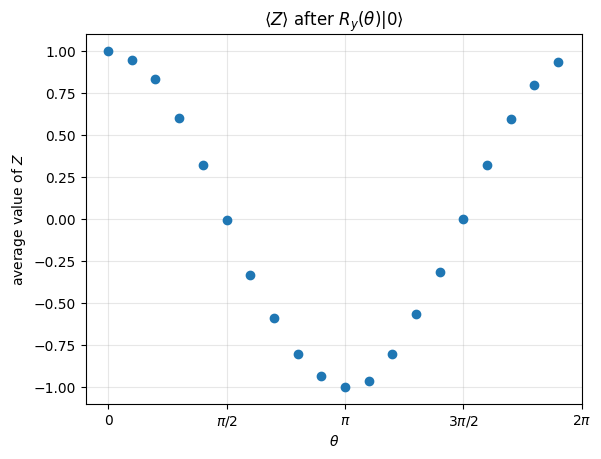

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

SHOTS = 2048
N_POINTS = 20

# 20 equally spaced points in [0, 2*pi); endpoint=False excludes 2*pi
thetas = np.linspace(0, 2 * np.pi, N_POINTS, endpoint=False)

sim = AerSimulator()
z_averages = []

for theta in thetas:
    # start in |0>, apply Ry(theta), measure in the computational basis
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    qc.measure_all()

    qc_transpiled = transpile(qc, sim)
    counts = sim.run(qc_transpiled, shots=SHOTS).result().get_counts()

    # Z eigenvalues: |0> -> +1, |1> -> -1
    n0 = counts.get("0", 0)
    n1 = counts.get("1", 0)
    z_averages.append((n0 - n1) / sum(counts.values()))
    # print(f"theta={theta:.3f}, n0={n0}, n1={n1}, z_avg={z_averages[-1]}")

# plot the average value of Z against theta
plt.plot(thetas, z_averages, "o")
plt.xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi], ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
plt.xlabel(r"$\theta$")
plt.ylabel(r"average value of $Z$")
plt.title(r"$\langle Z \rangle$ after $R_y(\theta)|0\rangle$")
plt.grid(alpha=0.3)
plt.show()